# Random Walk implementation (DeepWalk)

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import networkx as nx
import numpy as np
import random
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [ ]:
class GraphEmbedder(nn.Module):
    def __init__(self, num_nodes, embedding_dim):
        super(GraphEmbedder, self).__init__()
        self.embeddings = nn.Embedding(num_nodes, embedding_dim)
    def forward(self, node_ids):
        return self.embeddings(node_ids)


In [8]:
def drawGraphWithWalk(G,walk):
 pos=nx.kamada_kawai_layout(G)
 c,k=[],0
 for u,v in G.edges:
  found=False
  for k in range(len(walk)-1):
   if (walk[k]==u and walk[k+1]==v) or (walk[k]==v and walk[k+1]==u):
    found=True
    break
  if found: c.append('red')
  else: c.append('blue')
 nx.draw(G,pos,with_labels=True,edge_color=c)
 print(walk)

[29, 23, 25, 23, 27, 2, 7]


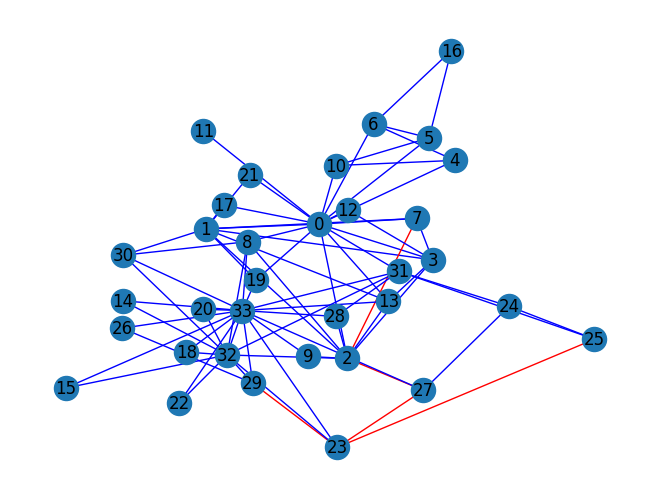

In [30]:
G = nx.karate_club_graph()

def generate_random_walks(G, num_walks=10, walk_length=80):
    walks = []
    nodes = list(G.nodes())
    for _ in range(num_walks):
        random.shuffle(nodes)
        node=nodes[0]
        walk = [node]
        for _ in range(walk_length - 1):
                curr = walk[-1]
                neighbors = list(G.neighbors(curr))
                if neighbors: walk.append(random.choice(neighbors))
                else: walk.append(curr)
        walks.append(walk)
    return walks

walks = generate_random_walks(G, num_walks=1, walk_length=7)
drawGraphWithWalk(G,walks[0])


In [19]:
def generate_training_pairs(nodes, walks, window_size=1, num_neg_samples=5):
    vocab_size, pairs = len(nodes), []
    for walk in walks:
        for i, center in enumerate(walk):
            start = max(0, i - window_size)
            end = min(len(walk), i + window_size + 1)
            for j in range(start, end):
                if i != j:
                    pos_ctx = walk[j]
                    pairs.append((center, pos_ctx, 1))  # Positive pair
                    for _ in range(num_neg_samples):
                        neg_ctx = random.randint(0, vocab_size - 1)
                        while neg_ctx == center or neg_ctx == pos_ctx:
                            neg_ctx = random.randint(0, vocab_size - 1)
                        pairs.append((center, neg_ctx, 0))  # Negative pair
    return window_size+num_neg_samples,pairs
batch,pairs=generate_training_pairs(list(G.nodes()), walks)
print(batch)

6


In [ ]:
print(pairs[0],pairs[1:batch])

(20, 32, 1) [(20, 24, 0), (20, 3, 0), (20, 0, 0), (20, 29, 0), (20, 3, 0)]


In [14]:
class GraphEmbedder(nn.Module):
    def __init__(self, num_nodes, embedding_dim):
        super(GraphEmbedder, self).__init__()
        self.embeddings = nn.Embedding(num_nodes, embedding_dim)
    def forward(self, node_ids):
        return self.embeddings(node_ids)

In [15]:
def contrastive_loss(pos_scores, neg_scores):
    loss=0
    if len(pos_scores) > 0: loss += -torch.log(torch.sigmoid(pos_scores) + 1e-15).sum()
    if len(neg_scores) > 0: loss += torch.log(torch.sigmoid(neg_scores) + 1e-15).sum()
    return loss

In [ ]:
num_nodes = G.number_of_nodes()
num_nodes

34

In [ ]:
walks = generate_random_walks(G, num_walks=7, walk_length=5)
walks

[[12, 3, 1, 21, 0],
 [5, 10, 5, 16, 5],
 [27, 23, 33, 29, 23],
 [17, 0, 2, 0, 31],
 [6, 0, 3, 13, 3],
 [31, 24, 31, 28, 31],
 [18, 32, 8, 32, 15]]

In [ ]:
nodes=list(G.nodes())
batch_size,pairs = generate_training_pairs(nodes, walks)
batch_size

6

In [ ]:
pairs = np.array(pairs)  # (N, 3): [center, context, label]
centers = torch.tensor(pairs[:, 0], dtype=torch.long).to(device)
contexts = torch.tensor(pairs[:, 1], dtype=torch.long).to(device)
labels = torch.tensor(pairs[:, 2], dtype=torch.float).to(device)

In [ ]:
embedding_dim,lr=3,1e-2
model = GraphEmbedder(num_nodes, embedding_dim).to(device)
optimizer = optim.SGD(model.parameters(), lr=lr)

In [ ]:
model.train()
num_epochs=1
for epoch in range(num_epochs):
    total_loss = 0.0
    for i in range(0, len(pairs), batch_size):
        batch_centers = centers[i:i+batch_size]
        batch_contexts = contexts[i:i+batch_size]
        batch_labels = labels[i:i+batch_size]
        optimizer.zero_grad()
        center_embeds = model(batch_centers)  # (B, d)
        context_embeds = model(batch_contexts)  # (B, d)
        print('c:',center_embeds)
        print('ct:',context_embeds)

        scores = torch.sum(center_embeds * context_embeds, dim=1)  # (B,)
        print('c*ct:',scores)

        pos_scores = scores[batch_labels == 1]
        neg_scores = scores[batch_labels == 0]
        print('pos:',pos_scores)
        print('neg:',neg_scores)

        loss = contrastive_loss(pos_scores,neg_scores)
        print('loss:',loss)
        break
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss:.4f}")


c: tensor([[-2.1559, -1.1720,  1.4451],
        [-2.1559, -1.1720,  1.4451],
        [-2.1559, -1.1720,  1.4451],
        [-2.1559, -1.1720,  1.4451],
        [-2.1559, -1.1720,  1.4451],
        [-2.1559, -1.1720,  1.4451]], grad_fn=<EmbeddingBackward0>)
ct: tensor([[ 0.0047,  0.4439,  0.4854],
        [-0.5982, -0.5817,  0.7885],
        [-0.7601,  0.0844,  0.1298],
        [-0.9877,  0.6369, -0.0207],
        [-0.0785, -0.1386,  1.2147],
        [ 0.9775,  0.0839,  0.9951]], grad_fn=<EmbeddingBackward0>)
c*ct: tensor([ 0.1711,  3.1109,  1.7272,  1.3530,  2.0871, -0.7676],
       grad_fn=<SumBackward1>)
pos: tensor([0.1711], grad_fn=<IndexBackward0>)
neg: tensor([ 3.1109,  1.7272,  1.3530,  2.0871, -0.7676], grad_fn=<IndexBackward0>)
loss: tensor(-1.0917, grad_fn=<AddBackward0>)
Epoch 1/1, Loss: 0.0000


In [ ]:
embedding_dim,lr=3,1e-2
model = GraphEmbedder(num_nodes, embedding_dim).to(device)
optimizer = optim.SGD(model.parameters(), lr=lr)

walks = generate_random_walks(G, num_walks=1000, walk_length=10)
nodes=list(G.nodes())
batch_size,pairs = generate_training_pairs(nodes, walks)
pairs = np.array(pairs)  # (N, 3): [center, context, label]
centers = torch.tensor(pairs[:, 0], dtype=torch.long).to(device)
contexts = torch.tensor(pairs[:, 1], dtype=torch.long).to(device)
labels = torch.tensor(pairs[:, 2], dtype=torch.float).to(device)


model.train()
num_epochs=10
for epoch in range(num_epochs):
    total_loss = 0.0
    for i in range(0, len(pairs), batch_size):
        batch_centers = centers[i:i+batch_size]
        batch_contexts = contexts[i:i+batch_size]
        batch_labels = labels[i:i+batch_size]
        optimizer.zero_grad()
        center_embeds = model(batch_centers)  # (B, d)
        context_embeds = model(batch_contexts)  # (B, d)
        scores = torch.sum(center_embeds * context_embeds, dim=1)  # (B,)
        pos_scores = scores[batch_labels == 1]
        neg_scores = scores[batch_labels == 0]
        loss = contrastive_loss(pos_scores,neg_scores)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss:.4f}")


Epoch 1/10, Loss: -1187405.0779
Epoch 2/10, Loss: -1292915.9489
Epoch 3/10, Loss: -1292919.7011
Epoch 4/10, Loss: -1292921.2016
Epoch 5/10, Loss: -1292922.0439
Epoch 6/10, Loss: -1292922.6271
Epoch 7/10, Loss: -1292923.1560
Epoch 8/10, Loss: -1292924.2011
Epoch 9/10, Loss: -1295727.7433
Epoch 10/10, Loss: -1301990.4741


In [ ]:
model.eval()
with torch.no_grad():
  embeddings = model.embeddings.weight.cpu().data.numpy()

In [ ]:
print("Embedding for node 1:", embeddings[1])
print("Shape:", embeddings[1].shape)

Embedding for node 1: [5.4137907  6.558103   0.88895667]
Shape: (3,)


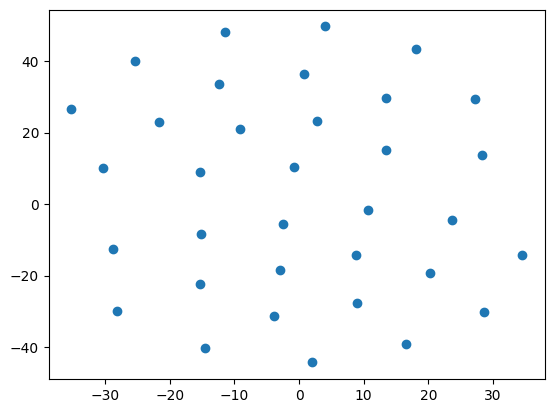

In [ ]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
tr=TSNE(n_components=2)
ne=tr.fit_transform(embeddings)
plt.scatter(ne[:,0],ne[:,1])

Text(0.5, 1.0, '19')

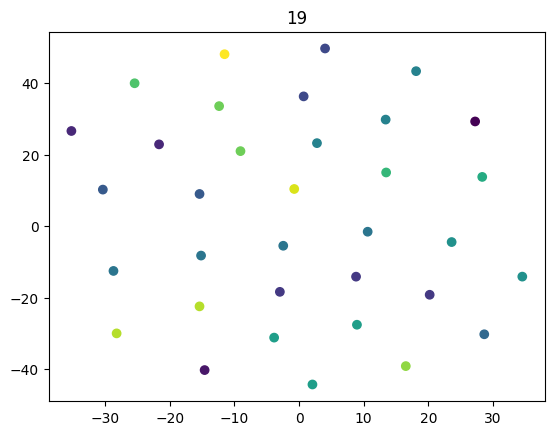

In [ ]:
from sklearn.mixture import GaussianMixture
gm_opt,gm_opt_bic,gm_opt_c,gm_opt_n=[],1e100,[],-1
for n in range(1,20):
 clf=GaussianMixture(n_components=n)
 c=clf.fit_predict(ne)
 bic=clf.bic(ne)
 if bic<gm_opt_bic:
  gm_opt=clf
  gm_opt_bic=bic
  gm_opt_c=c
  gm_opt_n=n
plt.scatter(ne[:,0],ne[:,1],c=gm_opt_c)
plt.title(str(gm_opt_n))

In [6]:
def drawGraphWithEmb(G,c):
 pos=nx.kamada_kawai_layout(G)
 nx.draw(G,pos,with_labels=True,node_color=c)
 print(c)
drawGraphWithEmb(G,gm_opt_c)

NameError: name 'gm_opt_c' is not defined

Text(0.5, 1.0, '2')

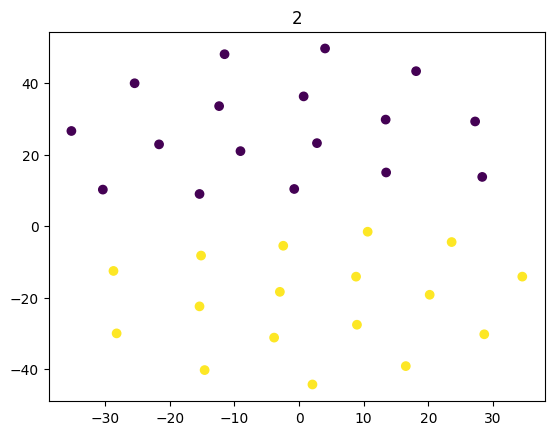

In [ ]:
n=2
clf=GaussianMixture(n_components=n)
c=clf.fit_predict(ne)
plt.scatter(ne[:,0],ne[:,1],c=c)
plt.title(str(n))

[0 0 1 1 1 1 0 1 1 1 0 0 1 0 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1 1 1 0]


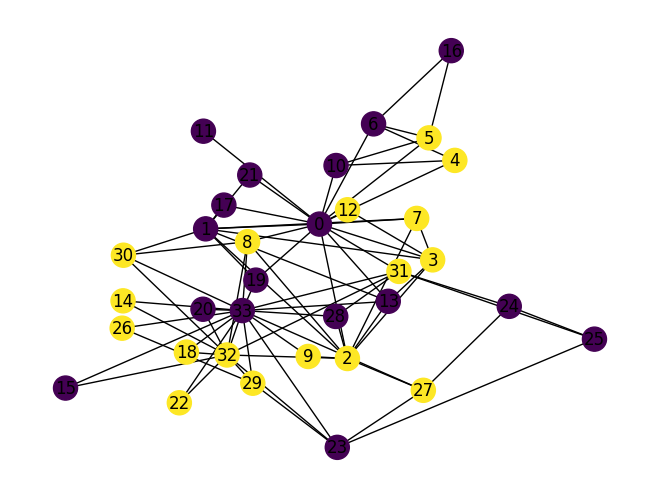

In [ ]:
drawGraphWithEmb(G,c)

Text(0.5, 1.0, '2')

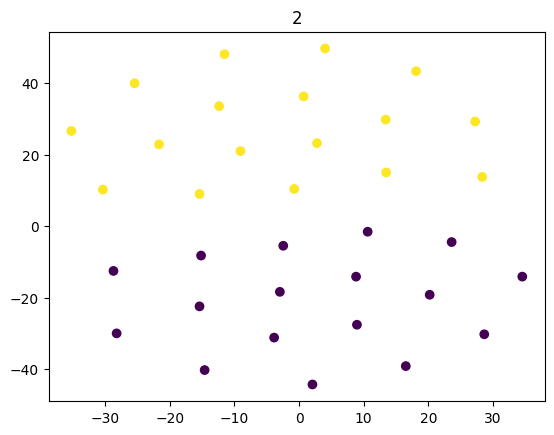

In [ ]:
n=2
clf=GaussianMixture(n_components=n)
c=clf.fit_predict(embeddings)
plt.scatter(ne[:,0],ne[:,1],c=c)
plt.title(str(n))

[1 1 0 0 0 0 1 0 0 0 1 1 0 1 0 1 1 1 0 1 1 1 0 1 1 1 0 0 1 0 0 0 0 1]


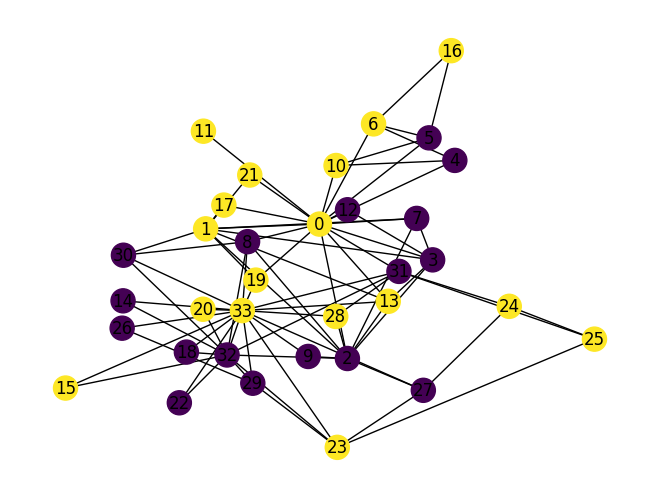

In [ ]:
drawGraphWithEmb(G,c)

# выбор траектории с Node2Vec

[21, 0, 31, 0, 21, 1]


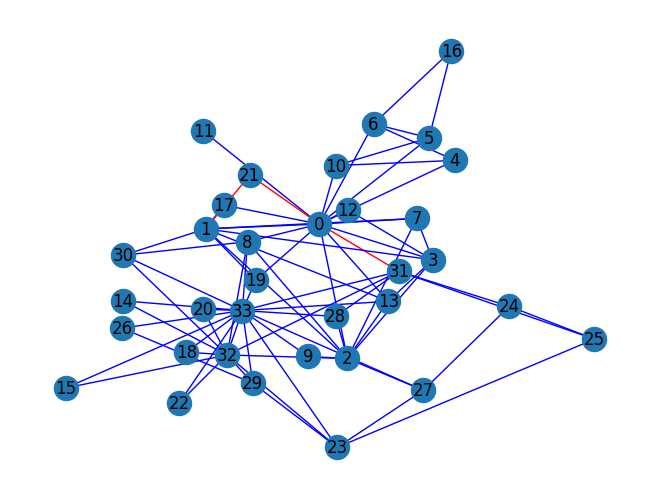

In [12]:
import random
import numpy as np
from collections import defaultdict

def get_alias_edge(G, p, q, src, dst):
    unnormalized_probs = []
    neighbors = sorted(G.neighbors(dst))
    for dst_nbr in neighbors:
        if dst_nbr == src:             unnormalized_probs.append(1/p)
        elif G.has_edge(dst_nbr, src): unnormalized_probs.append(1.0)
        else:                          unnormalized_probs.append(1/q)
    return create_alias_table(unnormalized_probs)

def generate_node2vec_walks(G, num_walks=10, walk_length=80, p=1.0, q=1.0):
    walks = []
    nodes = list(G.nodes())

    alias_nodes = {}
    alias_edges = {}
    # 1. Compute node transition probabilities (normalized 1st order)
    for node in nodes:
        probs = [1.0 for nbr in sorted(G.neighbors(node))]
        alias_nodes[node] = create_alias_table(probs)

    # 2. Compute edge transition probabilities (2nd order, depends on p/q)
    for node in nodes:
        for nbr in G.neighbors(node):
            key = (node, nbr)
            alias_edges[key] = get_alias_edge(G, p, q, node, nbr)

    # 3. Generate walks
    for _ in range(num_walks):
        random.shuffle(nodes)
        for start_node in nodes:
            walk = [start_node]
            walk=[]
            walk.extend(node2vec_walk(G, walk_length - 1, start_node, alias_nodes, alias_edges, p, q))
            walks.append(walk)

    return walks




def node2vec_walk(G, walk_length, start_node, alias_nodes, alias_edges, p=1.0, q=1.0):
    """
    Simulate a single node2vec random walk starting from start_node.
    """
    walk = [start_node]
    prev = -1  # dummy for first step
    curr = start_node

    for _ in range(walk_length - 1):
        curr_neighbors = list(G.neighbors(curr))
        if len(curr_neighbors) == 0:
            break

        if len(walk) == 1:  # First step: only depends on node weights
            next_node = alias_sample(alias_nodes[curr][0], alias_nodes[curr][1])
            next_node = curr_neighbors[next_node]
            walk.append(next_node)
            prev = curr
            curr = next_node
        else:
            prev = walk[-2]
            curr = walk[-1]
            key = (prev, curr)
            # Sample based on 2nd-order transition probabilities
            next_index = alias_sample(alias_edges[key][0], alias_edges[key][1])
            next_node = list(G.neighbors(curr))[next_index]
            walk.append(next_node)

    return walk


def create_alias_table(probs):
    if len(probs) == 0: return [], []

    probs = np.array(probs)
    probs = probs / probs.sum()  # normalize
    n = len(probs)

    J = np.zeros(n, dtype=np.int32)
    q = np.zeros(n)

    # Scale probabilities
    smaller = []
    larger = []
    for i, prob in enumerate(probs):
        q[i] = n * prob
        if q[i] < 1.0: smaller.append(i)
        else: larger.append(i)

    # Construct alias table
    while len(smaller) > 0 and len(larger) > 0:
        small = smaller.pop()
        large = larger.pop()

        J[small] = large
        q[large] = q[large] + q[small] - 1.0

        if q[large] < 1.0:
            smaller.append(large)
        else:
            larger.append(large)

    return J.tolist(), q.tolist()


def alias_sample(J, q):
#    if len(J) == 0:
#        return -1
    n = len(J)
    k = random.randint(0, n - 1)
    if random.random() < q[k]:
        return k
    else:
        return J[k]

walks = generate_node2vec_walks(G, num_walks=1, walk_length=7, p=3, q=1)
drawGraphWithWalk(G,walks[0])

In [20]:
num_nodes=34
embedding_dim,lr=3,1e-2
model = GraphEmbedder(num_nodes, embedding_dim).to(device)
optimizer = optim.SGD(model.parameters(), lr=lr)

walks = generate_node2vec_walks(G, num_walks=100, walk_length=7,p=1,q=1)
nodes=list(G.nodes())
batch_size,pairs = generate_training_pairs(nodes, walks)
pairs = np.array(pairs)  # (N, 3): [center, context, label]
centers = torch.tensor(pairs[:, 0], dtype=torch.long).to(device)
contexts = torch.tensor(pairs[:, 1], dtype=torch.long).to(device)
labels = torch.tensor(pairs[:, 2], dtype=torch.float).to(device)


model.train()
num_epochs=10
for epoch in range(num_epochs):
    total_loss = 0.0
    for i in range(0, len(pairs), batch_size):
        batch_centers = centers[i:i+batch_size]
        batch_contexts = contexts[i:i+batch_size]
        batch_labels = labels[i:i+batch_size]
        optimizer.zero_grad()
        center_embeds = model(batch_centers)  # (B, d)
        context_embeds = model(batch_contexts)  # (B, d)
        scores = torch.sum(center_embeds * context_embeds, dim=1)  # (B,)
        pos_scores = scores[batch_labels == 1]
        neg_scores = scores[batch_labels == 0]
        loss = contrastive_loss(pos_scores,neg_scores)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss:.4f}")


Epoch 1/10, Loss: -2386866.4102
Epoch 2/10, Loss: -2522935.9833
Epoch 3/10, Loss: -2522945.0145
Epoch 4/10, Loss: -2522948.2502
Epoch 5/10, Loss: -2522950.4686


KeyboardInterrupt: 

In [22]:
embeddings = model.embeddings.weight.cpu().data.numpy()

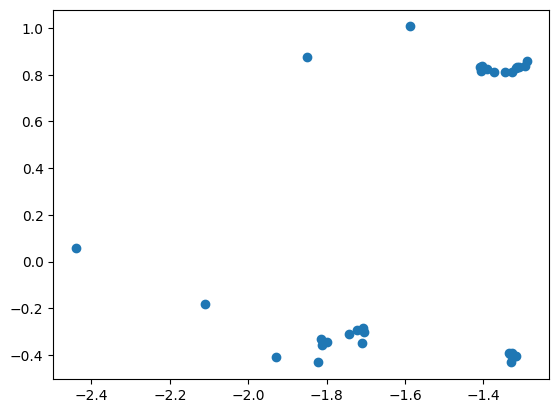

In [23]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
tr=TSNE(n_components=2)
ne=tr.fit_transform(embeddings)
plt.scatter(ne[:,0],ne[:,1])

Text(0.5, 1.0, '6')

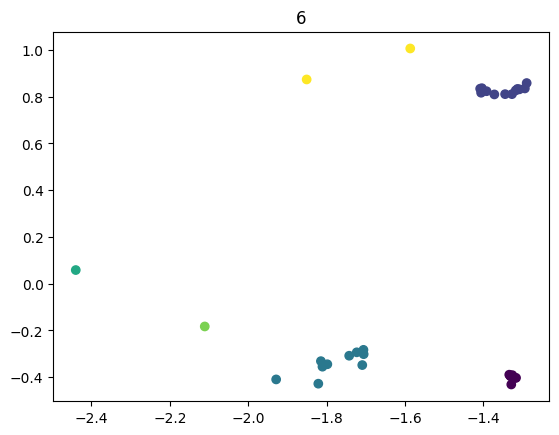

In [24]:
from sklearn.mixture import GaussianMixture
gm_opt,gm_opt_bic,gm_opt_c,gm_opt_n=[],1e100,[],-1
for n in range(1,20):
 clf=GaussianMixture(n_components=n)
 c=clf.fit_predict(ne)
 bic=clf.bic(ne)
 if bic<gm_opt_bic:
  gm_opt=clf
  gm_opt_bic=bic
  gm_opt_c=c
  gm_opt_n=n
plt.scatter(ne[:,0],ne[:,1],c=gm_opt_c)
plt.title(str(gm_opt_n))

[2 0 1 2 1 4 2 0 1 1 5 1 2 2 2 3 0 2 1 0 1 2 1 1 0 0 2 0 1 1 1 0 5 2]


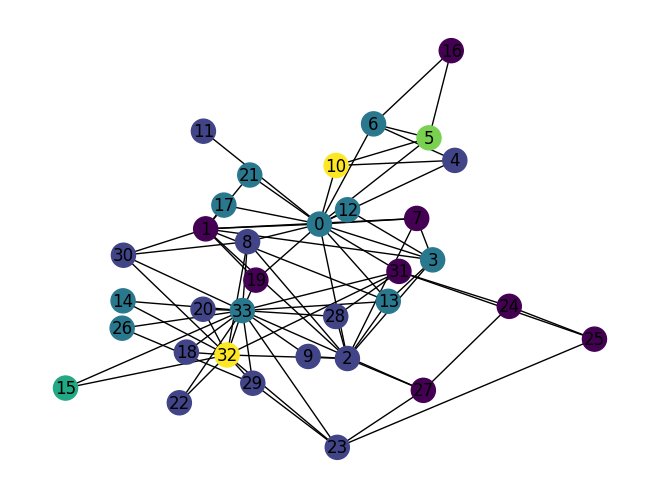

In [25]:
drawGraphWithEmb(G,gm_opt_c)

Text(0.5, 1.0, '2')

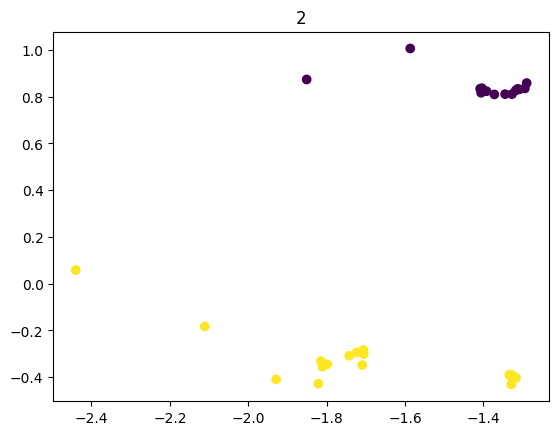

In [26]:
n=2
clf=GaussianMixture(n_components=n)
c=clf.fit_predict(embeddings)
plt.scatter(ne[:,0],ne[:,1],c=c)
plt.title(str(n))

[1 1 0 1 0 1 1 1 0 0 0 0 1 1 1 1 1 1 0 1 0 1 0 0 1 1 1 1 0 0 0 1 0 1]


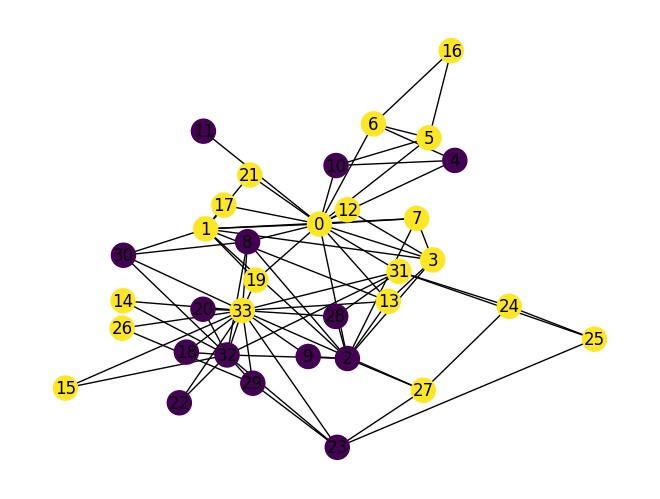

In [27]:
drawGraphWithEmb(G,c)

# Прогноз состояния ноды по ее окружению (эмбеддингу)

In [31]:
import networkx as nx
import numpy as np
G = nx.karate_club_graph()

def next_node(G, previous, current, p, q):
  neighbors = list(G.neighbors(current))
  alphas = []
  for neighbor in neighbors:
    if neighbor == previous: alpha = 1/p
    elif G.has_edge(neighbor, previous): alpha = 1
    else: alpha = 1/q
    alphas.append(alpha)
  probs = [alpha / sum(alphas) for alpha in alphas]
  next = np.random.choice(neighbors, size=1, p=probs)[0]
  return next

def random_walk(G, start, length, p, q):
  walk = [start]
  for i in range(length):
    current = walk[-1]
    previous = walk[-2] if len(walk) > 1 else None
    next = next_node(G, previous, current, p, q)
    walk.append(next)
  return [int(x) for x in walk]

walks=random_walk(G, 0, 8, p=0.0001, q=0.0001)
walks

[0, 10, 0, 3, 0, 8, 0, 19, 0]

In [ ]:
def drawGraphWithWalk(G,walk):
 pos=nx.kamada_kawai_layout(G)
 c,k=[],0
 for u,v in G.edges:
  found=False
  for k in range(len(walk)-1):
   if (walk[k]==u and walk[k+1]==v) or (walk[k]==v and walk[k+1]==u):
    found=True
    break
  if found: c.append('red')
  else: c.append('blue')
 nx.draw(G,pos,with_labels=True,edge_color=c)
 print(walk)

[0, 10, 0, 17, 0, 31, 24, 31, 32]


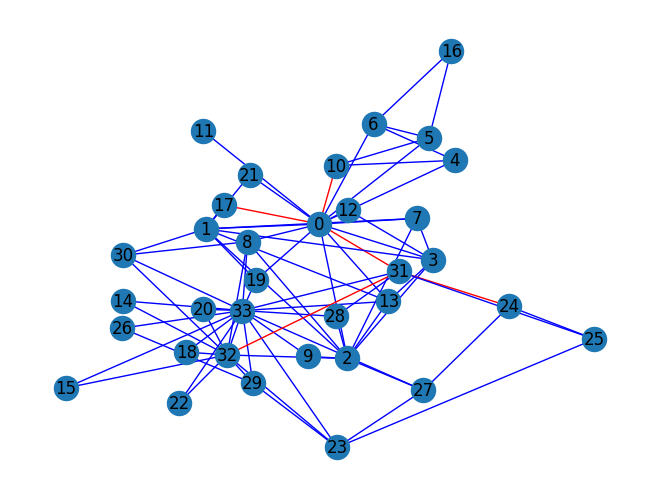

In [ ]:
drawGraphWithWalk(G,walks)

In [28]:
!pip install gensim

In [ ]:
# !pip install scipy

In [32]:
from gensim.models.word2vec import Word2Vec
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
labels = []
for node in G.nodes:
  label = G.nodes[node]['club']
  labels.append(1 if label == 'Officer' else 0)
walks = []
for node in G.nodes:
  for _ in range(80):
     walk = random_walk(G,node, 10, 3, 2)
     walk_str = [str(x) for x in walk]
     walks.append(walk_str)
node2vec = Word2Vec(walks,
  hs=1, # Hierarchical softmax
  sg=1, # Skip-gram
  vector_size=100,
  window=10,
  workers=2,
  min_count=1,
  seed=0)

In [33]:
node2vec.train(walks, total_examples=node2vec.corpus_count, epochs=30, report_delay=1)

(186611, 897600)

In [40]:
Gv=G.copy()
for node in range(34):
 Gv.add_edge(34,node)
walks = []
for node in Gv.nodes:
  for _ in range(80):
     walk = random_walk(Gv,node, 10, 3, 2)
     walk_str = [str(x) for x in walk]
     walks.append(walk_str)
node2vec = Word2Vec(walks, hs=1,
  sg=1, vector_size=100, window=10, 
  workers=2, min_count=1, seed=0)
node2vec.train(walks, total_examples=node2vec.corpus_count, \
      epochs=30, report_delay=1)
print('virt node emb:',node2vec.wv["34"])

virt node emb: [ 0.18692373  0.01190648  0.05383725 -0.12301093  0.01044455 -0.03022138
 -0.10084987 -0.10045151 -0.014161    0.12525576 -0.0862403   0.08683522
  0.05348392  0.07612101 -0.02511345  0.07137197  0.15731734 -0.02805318
  0.00229374  0.10238857 -0.06043416  0.07978882  0.07359398 -0.19530219
  0.19143298  0.1704341  -0.00042989 -0.20085618  0.02730528  0.00690256
  0.18748063 -0.12291073 -0.00758292  0.18387842 -0.16031449 -0.10270292
 -0.01535481 -0.0395583   0.00382384 -0.06921431 -0.08291938 -0.05641127
 -0.15966971 -0.07439096 -0.11664585  0.03956958 -0.04886102 -0.0208396
 -0.09491225  0.08804553  0.00882821 -0.04137711 -0.01304384  0.14234729
  0.08907516 -0.03062096 -0.12960635  0.10515683  0.15190819  0.02555932
  0.08473852  0.10025913  0.03517051 -0.02616062  0.03123054  0.00051836
 -0.10628847 -0.04975927  0.05823426 -0.0352236  -0.14456546  0.08929443
 -0.11208566  0.03959214  0.0707076   0.1326063  -0.06095421  0.09723103
  0.08021626  0.00398621  0.12821373 

In [39]:
print('virt node emb:',node2vec.wv[33])

virt node emb: [ 0.26993722 -0.08657639  0.20703144  0.1399572  -0.09430979  0.03971465
  0.06616534 -0.18554269 -0.02480418  0.21705574 -0.18765524  0.0428819
  0.12137774 -0.111119    0.05079993  0.0608145   0.3005394   0.24145265
 -0.235268    0.3040743  -0.30359638  0.11233467  0.01063844  0.01759627
  0.09345895  0.21880692  0.00898713  0.05575439 -0.11132875 -0.36984584
  0.1700077  -0.14768845  0.16023643  0.08150486 -0.26476988  0.01850334
  0.16379598  0.20992993 -0.07671357  0.24961475 -0.18005186  0.05735889
 -0.07784572 -0.11914658 -0.21365614 -0.09404146 -0.15930144 -0.11610287
  0.16932768  0.14491773 -0.05591476  0.06615135  0.14490202  0.15285607
  0.0105855  -0.08015207  0.00934716 -0.03799553 -0.3005797  -0.04620054
  0.02219632  0.3604683  -0.03502615  0.08183447  0.03839139  0.13457845
  0.14236459 -0.40209204  0.27817503 -0.03899586 -0.06021516 -0.10563036
 -0.31466967 -0.14110388  0.05134866 -0.18963495  0.01150611 -0.02229053
  0.03454938  0.09996369 -0.06643032 

In [ ]:
train_mask = list(range(0,34,2))
train_mask_str = [str(x) for x in train_mask]
test_mask = list(range(1,34,2))
test_mask_str = [str(x) for x in test_mask]
labels = np.array(labels)

In [ ]:
clf = RandomForestClassifier(random_state=0)
clf.fit(node2vec.wv[train_mask_str], labels[train_mask])
y_pred = clf.predict(node2vec.wv[test_mask_str])
acc = accuracy_score(y_pred, labels[test_mask])
print(f'Node2Vec accuracy = {acc*100:.2f}%')

Node2Vec accuracy = 100.00%


In [ ]:
def drawGraphWithEmb(G,c):
 pos=nx.kamada_kawai_layout(G)
 nx.draw(G,pos,with_labels=True,node_color=c)
 print(c)


[0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1]
[0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1]


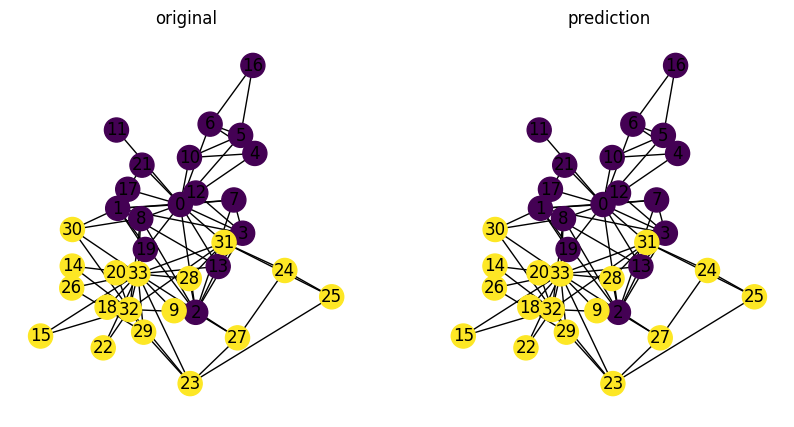

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.title('original')
drawGraphWithEmb(G,labels)
c_pred = clf.predict(node2vec.wv[[str(x) for x in range(34)]])
plt.subplot(1,2,2)
plt.title('prediction')
drawGraphWithEmb(G,c_pred)

# Movie recomender system

In [ ]:
!pip install node2vec

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.6/26.6 MB 63.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 88.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.2/38.2 MB 18.0 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.1
    Uninstalling scipy-1.16.1:
      Successfully uninstalled scipy-1.16.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
openc

In [ ]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import pandas as pd
from collections import defaultdict
from node2vec import Node2Vec
import networkx as nx

In [ ]:
url = 'https://files.grouplens.org/datasets/movielens/ml-100k.zip'
zurl=urlopen(url)
zfile=ZipFile(BytesIO(zurl.read()))
zfile.extractall('.')
ratings = pd.read_csv('ml-100k/u.data', sep='\t',names=['user_id', 'movie_id', 'rating', 'unix_timestamp'])
ratings

,user_id,movie_id,rating,unix_timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596
...,...,...,...,...
99995,880,476,3,880175444
99996,716,204,5,879795543
99997,276,1090,1,874795795
99998,13,225,2,882399156


In [ ]:
movies = pd.read_csv('ml-100k/u.item', sep='|',usecols=range(2), names=['movie_id', 'title'],encoding='latin-1')
movies

,movie_id,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)
...,...,...
1677,1678,Mat' i syn (1997)
1678,1679,B. Monkey (1998)
1679,1680,Sliding Doors (1998)
1680,1681,You So Crazy (1994)


## Идея: если пользователь высоко рейтингует два фильма - то их степень похожести увеличивается. Фильмы с макисмальной степенью похожести (5% от всех возможных пар) образуют граф.

In [ ]:
ratings = ratings[ratings.rating >= 4]
ratings

,user_id,movie_id,rating,unix_timestamp
5,298,474,4,884182806
7,253,465,5,891628467
11,286,1014,5,879781125
12,200,222,5,876042340
16,122,387,5,879270459
...,...,...,...,...
99988,421,498,4,892241344
99989,495,1091,4,888637503
99990,806,421,4,882388897
99991,676,538,4,892685437


In [ ]:
pairs = defaultdict(int)
for group in ratings.groupby("user_id"):
  user_movies = list(group[1]["movie_id"])
  for i in range(len(user_movies)):
    for j in range(i+1, len(user_movies)):
      pairs[(user_movies[i], user_movies[j])]+= 1
pairs

defaultdict(int,
            {(61, 33): 4,
             (61, 160): 6,
             (61, 20): 4,
             (61, 202): 4,
             (61, 171): 6,
             (61, 265): 8,
             (61, 47): 5,
             (61, 222): 2,
             (61, 253): 1,
             (61, 113): 3,
             (61, 227): 3,
             (61, 90): 2,
             (61, 64): 10,
             (61, 228): 8,
             (61, 121): 4,
             (61, 114): 2,
             (61, 132): 9,
             (61, 134): 10,
             (61, 98): 13,
             (61, 186): 9,
             (61, 221): 5,
             (61, 84): 1,
             (61, 60): 18,
             (61, 177): 7,
             (61, 174): 12,
             (61, 82): 5,
             (61, 56): 12,
             (61, 80): 1,
             (61, 229): 2,
             (61, 235): 2,
             (61, 6): 2,
             (61, 206): 2,
             (61, 76): 1,
             (61, 72): 2,
             (61, 185): 11,
             (61, 96): 8,
             (61, 25

16.0


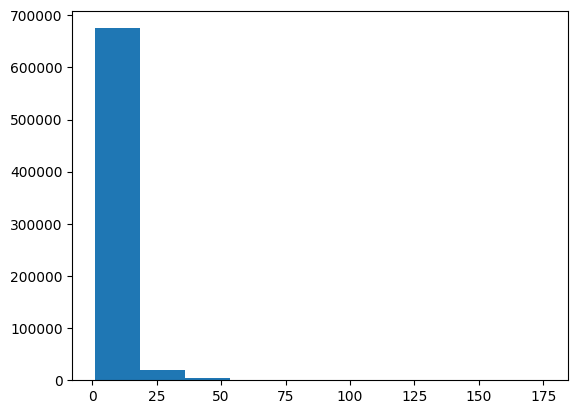

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
scores=[]
for pair in pairs:
 scores.append(pairs[pair])
plt.hist(scores)
print(np.percentile(np.array(scores),95))

In [1]:
G = nx.Graph()
for pair in pairs:
 movie1, movie2 = pair
 score = pairs[pair]
 if score >= 16:
  G.add_edge(movie1, movie2, weight=score)

NameError: name 'nx' is not defined

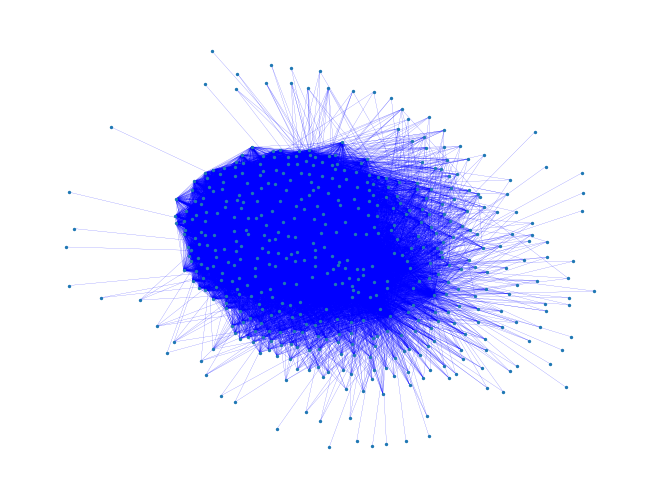

In [ ]:
pos=nx.kamada_kawai_layout(G)
nx.draw(G,pos,with_labels=False,node_size=2,edge_color='blue',width=0.1)

In [ ]:
node2vec = Node2Vec(G, dimensions=64, walk_length=20,num_walks=200, p=2, q=1, workers=1)
model = node2vec.fit(window=10, min_count=1,batch_words=4)

Computing transition probabilities:   0%|          | 0/490 [00:00<?, ?it/s]

Generating walks (CPU: 1): 100%|██████████| 200/200 [01:02<00:00,  3.21it/s]


In [ ]:
movies[movies.title == 'Toy Story (1995)']

,movie_id,title
0,1,Toy Story (1995)


In [ ]:
def recommend(movie):
 movie_id = str(movies[movies.title == movie].movie_id.values[0])
 for id in model.wv.most_similar(movie_id)[:5]:
  title = movies[movies.movie_id == int(id[0])].title.values[0]
  print(f'{title}: {id[1]:.2f}')
 return movie_id
recommend('Toy Story (1995)')

Return of the Jedi (1983): 0.63
Rock, The (1996): 0.57
Blues Brothers, The (1980): 0.56
Twelve Monkeys (1995): 0.56
Star Trek: First Contact (1996): 0.55


'1'

In [ ]:
recommend('Star Wars (1977)')

Return of the Jedi (1983): 0.67
Princess Bride, The (1987): 0.50
Toy Story (1995): 0.49
Raiders of the Lost Ark (1981): 0.48
Monty Python and the Holy Grail (1974): 0.47


'50'

# Entire graph embedding

## Averaging

In [ ]:

print(node2vec.wv[[str(x) for x in range(34)]])
print(node2vec.wv[[str(x) for x in range(34)]].shape)
print('entire graph:')
print(node2vec.wv[[str(x) for x in range(34)]].sum(axis=0))


[[ 0.25603536 -0.09525851  0.10149703 ... -0.15917644  0.0682245
   0.09141557]
 [ 0.16479717 -0.07204246  0.22710219 ... -0.20699543 -0.01311352
   0.15193161]
 [ 0.05099628 -0.19841428 -0.06888265 ...  0.00531026  0.05261438
   0.21267238]
 ...
 [ 0.15188134  0.21582483  0.06397925 ...  0.01123709  0.1272582
   0.36821875]
 [-0.01176392  0.07851475 -0.13828741 ...  0.10014865  0.21641634
   0.3727376 ]
 [ 0.03348516  0.13214782 -0.11328317 ...  0.16182458  0.13310498
   0.3270584 ]]
(34, 100)
entire graph:
[ 5.0194774  -3.0247285   1.2139859  -2.0896423   1.4458939  -1.4573091
 -4.2574196  -6.107485    1.3915242   2.1681662   1.7636368   0.532627
  3.70372     1.0997198   0.05861789 -0.31345993  2.9771073  -1.7016925
 -0.69501656  1.6622486  -2.9197614   3.4125328   1.1630592  -3.6833212
  9.531529    6.19006     0.04728083 -3.3548512  -0.01050928 -0.35995442
  2.617065    0.265358    4.4955916   1.9446579  -7.5794706   1.8416635
  2.3724859   2.9065175  -0.73310524 -1.1717194   1.30

## Virtual node

In [ ]:
Gv=G.copy()
for node in range(34):
 Gv.add_edge(34,node)
Gv

In [ ]:
walks=random_walk(Gv, 34, 8, p=0.0001, q=0.0001)
walks = []
for node in Gv.nodes:
  for _ in range(80):
     walk = random_walk(Gv,node, 10, 3, 2)
     walk_str = [str(x) for x in walk]
     walks.append(walk_str)
node2vec = Word2Vec(walks,
  hs=1, # Hierarchical softmax
  sg=1, # Skip-gram
  vector_size=100,
  window=10,
  workers=2,
  min_count=1,
  seed=0)
node2vec.train(walks, total_examples=node2vec.corpus_count, epochs=30, report_delay=1)
print('virt node emb:',node2vec.wv["34"])

virt node emb: [ 0.11476431 -0.03860929 -0.1327752  -0.08090994  0.08728423 -0.11830759
 -0.2053749  -0.09453807  0.009974    0.105594   -0.048609   -0.00182038
 -0.00087292  0.00265749  0.22859955  0.14944606  0.18155664 -0.12147112
  0.03577587  0.1707954  -0.09501309  0.16370232  0.074655   -0.1084362
  0.20594557  0.22739266  0.01528776 -0.27408454  0.05042635  0.09083325
  0.16929618 -0.07836474  0.0178069   0.14276023 -0.19541329  0.02827315
 -0.04135035  0.08739087 -0.14121595 -0.09442706 -0.00438582 -0.10523175
 -0.04970022 -0.07530127 -0.14795788 -0.00428677 -0.14646004  0.09641501
  0.00461847  0.07700512 -0.10455248  0.02073456 -0.08011804  0.1705798
 -0.10578363  0.1566372   0.04534569  0.06224832  0.09296849  0.07711581
  0.02604382  0.09769466  0.02766019  0.07168665  0.13508253  0.01308439
 -0.15226015  0.07503801  0.06649902  0.07620358 -0.05430521 -0.04648375
  0.00548199 -0.01110633  0.13106084  0.04471574 -0.09385084  0.05709305
  0.05613888 -0.00093802  0.08831415  

## Anonymous walk

In [ ]:
def random_anonymous_walk(G, start, length, p, q):
  walk = [0]
  encoder,enc_max={},0
  encoder[start]=0
  for i in range(length):
    current = walk[-1]
    previous = walk[-2] if len(walk) > 1 else None
    next = next_node(G, previous, current, p, q)
    if next not in encoder:
      enc_max+=1
      encoder[next]=enc_max
    walk.append(encoder[next])
  return [int(x) for x in walk],encoder
print(random_walk(G,30, 10, 3, 2))
print(random_anonymous_walk(G,30, 10, 3, 2))


[30, 32, 8, 33, 29, 23, 32, 31, 32, 30, 8]
([0, 1, 2, 3, 4, 3, 3, 1, 5, 3, 2], {30: 0, 1: 1, 2: 2, 0: 3, 7: 4, 13: 5})
['0 1 2 3', '0 1 2 3', '0 1 1 2', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 2', '0 1 2 3', '0 1 2 0', '0 1 0 1', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 0', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 0', '0 1 0 2', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 0 2', '0 1 0 2', '0 1 2 0', '0 1 2 3', '0 1 2 2', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 0', '0 1 2 1', '0 1 1 2', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 1 2', '0 1 2 3', '0 1 2 3', '0 1 1 2', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 2', '0 1 2 3', '0 1 2 2', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 0', '0 1 1 2', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 3', '0 1 2 2', '0 1 2 3', '0 1 2 2', '0 1 2 3', '0 1 2 3', '0 1 2 0', 

In [ ]:
walks = []
for node in G.nodes:
  for _ in range(80):
     walk,code = random_anonymous_walk(G,node, 2, 3, 2)
     walk_str = ' '.join([str(x) for x in walk])
     walks.append(walk_str)
print(walks)

['0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 1', '0 1 2', '0 1 0', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 1', '0 1 2', '0 1 1', '0 1 2', '0 1 2', '0 1 2', '0 1 1', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 0 1', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 1', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', '0 1 2', 

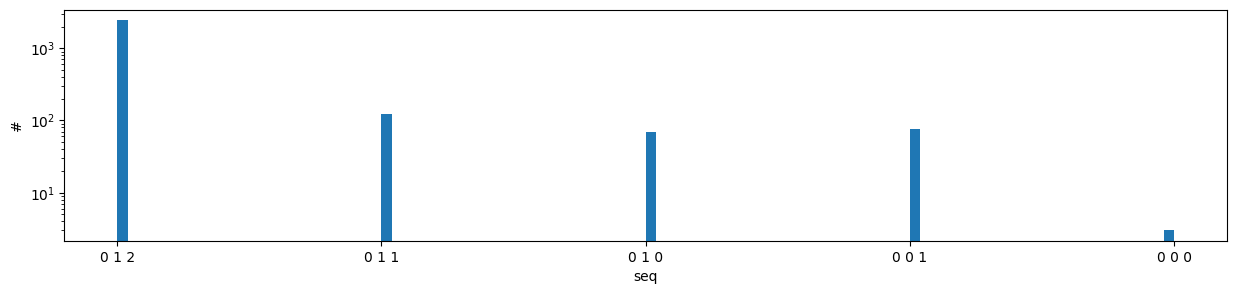

In [ ]:
plt.figure(figsize=(15,3))
plt.hist(walks,bins=100);
plt.xlabel('seq')
plt.ylabel('#')
plt.yscale('log')

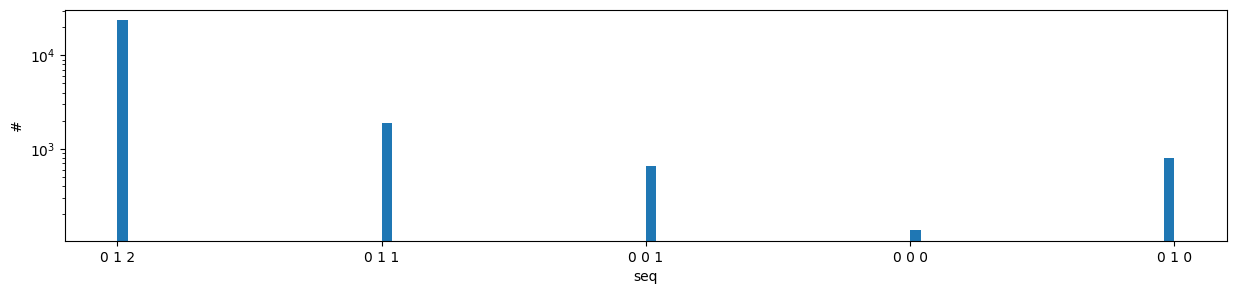

In [ ]:
G2=nx.erdos_renyi_graph(34,0.1)
walks = []
for node in G2.nodes:
  for _ in range(800):
     walk,code = random_anonymous_walk(G2,node, 2, 3, 2)
     walk_str = ' '.join([str(x) for x in walk])
     walks.append(walk_str)
plt.figure(figsize=(15,3))
plt.hist(walks,bins=100);
plt.xlabel('seq')
plt.ylabel('#')
plt.yscale('log')

#PageRank

In [1]:
import numpy as np

M=np.array([[0.5,0.5,0],[0.5,0,0],[0,0.5,1]])
Nm=1/3*np.array([[1,1,1],[1,1,1],[1,1,1]])
print(M)
print(Nm)


[[0.5 0.5 0. ]
 [0.5 0.  0. ]
 [0.  0.5 1. ]]
[[0.33333333 0.33333333 0.33333333]
 [0.33333333 0.33333333 0.33333333]
 [0.33333333 0.33333333 0.33333333]]


In [2]:
b=0.8
G=b*M+(1-b)*Nm
G

array([[0.46666667, 0.46666667, 0.06666667],
       [0.46666667, 0.06666667, 0.06666667],
       [0.06666667, 0.46666667, 0.86666667]])

In [ ]:
G=b*M+(1-b)*Nm
for i in range(10):
  Gold=G.copy()
  G=G@G
  print('\nitt:',i,'\nres:\n',G)
  if ((np.abs(G-Gold)<1e-10).all()):
    print('converged')
    break


itt: 0 
res:
 [[0.44       0.28       0.12      ]
 [0.25333333 0.25333333 0.09333333]
 [0.30666667 0.46666667 0.78666667]]

itt: 1 
res:
 [[0.30133333 0.25013333 0.17333333]
 [0.20426667 0.17866667 0.12746667]
 [0.4944     0.5712     0.6992    ]]

itt: 2 
res:
 [[0.22759168 0.219072   0.20530944]
 [0.16106752 0.15582464 0.14730496]
 [0.6113408  0.62510336 0.6473856 ]]

itt: 3 
res:
 [[0.21259739 0.2123354  0.21191149]
 [0.15180945 0.15164753 0.15138553]
 [0.63559316 0.63601707 0.63670298]]

itt: 4 
res:
 [[0.21212166 0.21212142 0.21212101]
 [0.15151543 0.15151528 0.15151503]
 [0.63636291 0.63636331 0.63636396]]

itt: 5 
res:
 [[0.21212121 0.21212121 0.21212121]
 [0.15151515 0.15151515 0.15151515]
 [0.63636364 0.63636364 0.63636364]]

itt: 6 
res:
 [[0.21212121 0.21212121 0.21212121]
 [0.15151515 0.15151515 0.15151515]
 [0.63636364 0.63636364 0.63636364]]
converged


In [7]:
import networkx as nx
G1 = nx.DiGraph()
for i in range(M.shape[0]):
  for j in range(M.shape[1]):
     G1.add_edge(i,j,weight=M[j,i])
print(G1)

DiGraph with 3 nodes and 9 edges


In [10]:
A = nx.adjacency_matrix(G1).toarray()
print(A)

[[0.5 0.5 0. ]
 [0.5 0.  0.5]
 [0.  0.  1. ]]


In [9]:
# G = nx.barabasi_albert_graph(60, 41)
pr = nx.pagerank(G1, b)
pr

{0: 0.21212254941844777, 1: 0.1515159780102962, 2: 0.636361472571256}

# Отображение двудольных графов


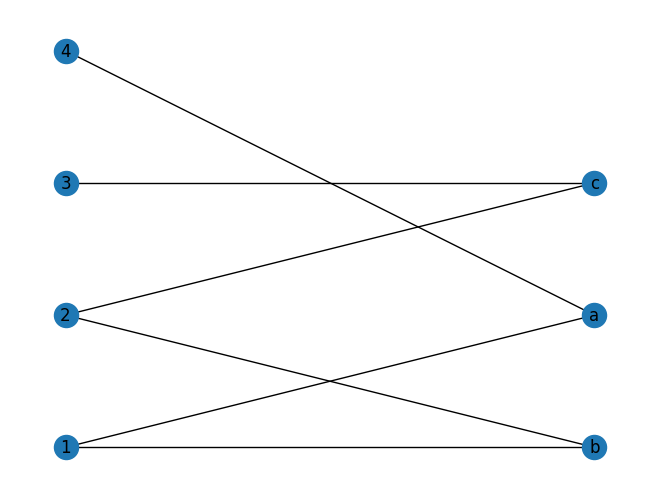

In [12]:
import networkx as nx
import matplotlib.pyplot as plt
B = nx.Graph()
B.add_nodes_from([1,2,3,4], bipartite=0) # Add the node attribute "bipartite"
B.add_nodes_from(['a','b','c'], bipartite=1)
B.add_edges_from([(1,'a'), (1,'b'), (2,'b'), (2,'c'), (3,'c'), (4,'a')])

l, r = nx.bipartite.sets(B)
pos = {}

pos.update((node, (1, index)) for index, node in enumerate(l))
pos.update((node, (2, index)) for index, node in enumerate(r))

nx.draw(B, pos=pos, with_labels=True)
plt.show()

# Random walk with restarts

In [ ]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import pandas as pd
from collections import defaultdict
import networkx as nx

In [ ]:
url = 'https://files.grouplens.org/datasets/movielens/ml-100k.zip'
zurl=urlopen(url)
zfile=ZipFile(BytesIO(zurl.read()))
zfile.extractall('.')
ratings = pd.read_csv('ml-100k/u.data', sep='\t',names=['user_id', 'movie_id', 'rating', 'unix_timestamp'])
ratings

,user_id,movie_id,rating,unix_timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596
...,...,...,...,...
99995,880,476,3,880175444
99996,716,204,5,879795543
99997,276,1090,1,874795795
99998,13,225,2,882399156


In [ ]:
movies = pd.read_csv('ml-100k/u.item', sep='|',usecols=range(2), names=['movie_id', 'title'],encoding='latin-1')
movies

,movie_id,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)
...,...,...
1677,1678,Mat' i syn (1997)
1678,1679,B. Monkey (1998)
1679,1680,Sliding Doors (1998)
1680,1681,You So Crazy (1994)


In [ ]:
ratings = ratings[ratings.rating >= 4]
ratings

,user_id,movie_id,rating,unix_timestamp
5,298,474,4,884182806
7,253,465,5,891628467
11,286,1014,5,879781125
12,200,222,5,876042340
16,122,387,5,879270459
...,...,...,...,...
99988,421,498,4,892241344
99989,495,1091,4,888637503
99990,806,421,4,882388897
99991,676,538,4,892685437


In [ ]:
UIDS=np.unique(ratings.user_id)
UIDS

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

In [ ]:
MIDS=np.unique(ratings.movie_id)
MIDS

array([   1,    2,    3, ..., 1662, 1664, 1674])

In [3]:
B = nx.Graph()
for x in  list(UIDS): B.add_node('u'+str(x),weight=0, bipartite=1) # Add the node attribute "bipartite"
for x in  list(MIDS): B.add_node('m'+str(x),weight=0,  bipartite=0)
for i in range(ratings.shape[0]):
#for i in range(1000):
 if np.random.rand()<0.01:
  B.add_edge('m'+str(ratings.iloc[i].movie_id),'u'+str(ratings.iloc[i].user_id))

l=['m'+str(x) for x in list(MIDS)]
r=['u'+str(x) for x in list(UIDS)]
pos = {}

pos.update((node, (1, index)) for index, node in enumerate(l))
pos.update((node, (2, index)) for index, node in enumerate(r))

nx.draw(B, pos=pos,node_size=1)
plt.show()

NameError: name 'nx' is not defined

In [4]:
alpha=0.1
for Q in B.nodes:
  q=Q
  for i in range(100):
    ns=list(B.neighbors(q))
    if ns:
     item=np.random.choice(ns)
     ns=list(B.neighbors(item))
     if ns:
      q=np.random.choice(ns)
      B.nodes[q]['weight']+=1
      if np.random.rand()<alpha:
        q=Q
  break
for Q in B.nodes:
  if B.nodes[Q]['bipartite']==1:
    print(Q,B.nodes[Q]['weight'])

NameError: name 'B' is not defined

# Связь с факторизацией матриц

## Факторизация для мелкого эмбеддинга

### Решение через разложение Холецкого  
работает для симметричных матриц с положительными собственными значениями

In [13]:
import numpy as np
A = np.array([[1, 1, 0.1 ], [1,2,1], [0.1, 1, 2]])
print(A)
B=np.linalg.cholesky(A)
B@B.T

[[1.  1.  0.1]
 [1.  2.  1. ]
 [0.1 1.  2. ]]


array([[1. , 1. , 0.1],
       [1. , 2. , 1. ],
       [0.1, 1. , 2. ]])

In [35]:
import networkx as nx
G=nx.karate_club_graph()
A = nx.adjacency_matrix(G).toarray()
A=A+1e-1
B=np.linalg.cholesky(A)
B

LinAlgError: Matrix is not positive definite

In [14]:
A = np.array([[0.1, 1, 0.1 ], [1,2,1], [0.1, 1, 2]])
print(A)
B=np.linalg.cholesky(A)
B@B.T

[[0.1 1.  0.1]
 [1.  2.  1. ]
 [0.1 1.  2. ]]


LinAlgError: Matrix is not positive definite

### Решение через собственные вектора и значения

In [21]:
import numpy as np
from scipy.linalg import eigh

# A = np.array([[0, 1, 0 ], [1,0,1], [0, 1, 0]])
A = np.array([[0.1, 1, 0.1 ], [1,2,1], [0.1, 1, 2]])

eigenvalues, eigenvectors = eigh(A)
eigenvalues = np.maximum(eigenvalues, 0)
sqrt_eigenvalues = np.sqrt(eigenvalues)
B = eigenvectors @ np.diag(sqrt_eigenvalues)

# Verify the result
print("A:\n", A,'\n')
print("B:\n", np.round(B,2),'\n')
print("B @ B.T:\n", B @ B.T,'\n')

A:
 [[0.1 1.  0.1]
 [1.  2.  1. ]
 [0.1 1.  2. ]] 

B:
 [[ 0.   -0.43 -0.46]
 [ 0.   -0.59 -1.31]
 [ 0.    0.86 -1.13]] 

B @ B.T:
 [[0.39507846 0.85526229 0.14853711]
 [0.85526229 2.07099469 0.97619226]
 [0.14853711 0.97619226 2.00798381]] 



In [37]:
import numpy as np
from sklearn.decomposition import NMF
A = np.array([[0.1, 1, 0.1 ], [1,2,1], [0.1, 1, 2]])
rank = 2  # Example rank
model = NMF(n_components=rank, init='random', random_state=0)
W = model.fit_transform(A)
HT = model.components_
B=W
print("A:")
print(A)
print("B:")
print(B)
#print("H:")
#print(HT)
print("B BT:")
print(B @ B.T)
print("W HT:")
print(W @ HT)


A:
[[0.1 1.  0.1]
 [1.  2.  1. ]
 [0.1 1.  2. ]]
B:
[[0.38039978 0.05454056]
 [0.78369285 0.3921988 ]
 [0.02451204 0.83788218]]
B BT:
[[0.14767867 0.31950733 0.05502294]
 [0.31950733 0.76799439 0.3478263 ]
 [0.05502294 0.3478263  0.70264739]]
W HT:
[[0.3950859  0.85529931 0.1485116 ]
 [0.85523368 2.07098877 0.97620068]
 [0.14855459 0.97619038 2.00798229]]


## Random walk factorization

In [66]:
A = np.array([[0.1, 1, 0.1 ], [1,2,1], [0.1, 1, 2]])
G=A.sum()
T=3
D=np.diag((A.sum(axis=-1)+A.sum(axis=0))/2)
T,G,D

(3,
 np.float64(8.3),
 array([[1.2, 0. , 0. ],
        [0. , 4. , 0. ],
        [0. , 0. , 3.1]]))

In [70]:
P=np.diag([1]*A.shape[0])
for i in range(T):
   P=P@(np.linalg.inv(D)@A)
P=G/T*(P@np.linalg.inv(D))
kneg=0.1
M=np.log(P)-np.log(kneg)
M

array([[1.27416215, 1.28942873, 1.04935135],
       [1.28942873, 1.23438554, 1.12668202],
       [1.04935135, 1.12668202, 1.34497663]])

In [71]:
eigenvalues, eigenvectors = eigh(M)
eigenvalues = np.maximum(eigenvalues, 0)
sqrt_eigenvalues = np.sqrt(eigenvalues)
B = eigenvectors @ np.diag(sqrt_eigenvalues)
print("A:\n", M,'\n')
print("B:\n", np.round(B,2),'\n')
print("B @ B.T:\n", B @ B.T,'\n')

A:
 [[1.27416215 1.28942873 1.04935135]
 [1.28942873 1.23438554 1.12668202]
 [1.04935135 1.12668202 1.34497663]] 

B:
 [[ 0.   -0.28 -1.1 ]
 [ 0.   -0.15 -1.11]
 [ 0.    0.45 -1.07]] 

B @ B.T:
 [[1.29209945 1.26790286 1.05325916]
 [1.26790286 1.26021791 1.12199241]
 [1.05325916 1.12199241 1.34582798]] 



In [43]:
import numpy as np
A = np.array([[1, 1, 0.1 ], [1,2,1], [0.1, 1, 2]])
print(A)  
B=np.linalg.cholesky(A)
print(B)
print(B@B.T)

[[1.  1.  0.1]
 [1.  2.  1. ]
 [0.1 1.  2. ]]
[[1.         0.         0.        ]
 [1.         1.         0.        ]
 [0.1        0.9        1.08627805]]
[[1.  1.  0.1]
 [1.  2.  1. ]
 [0.1 1.  2. ]]


In [44]:
import numpy as np
from sklearn.decomposition import NMF

model = NMF(n_components=2, init='random', random_state=0)
W = model.fit_transform(A)
HT = model.components_
B=W
print("B BT:\n",B @ B.T)


B BT:
 [[0.42594491 0.54702409 0.02278971]
 [0.54702409 0.85804675 0.34158521]
 [0.02278971 0.34158521 0.62839684]]


In [45]:
from scipy.linalg import eigh
eigenvalues, eigenvectors = eigh(A)
eigenvalues = np.maximum(eigenvalues, 0)
sqrt_eigenvalues = np.sqrt(eigenvalues)
B = eigenvectors @ np.diag(sqrt_eigenvalues)

print("A:\n", A,'\n')
print("B:\n", np.round(B,2),'\n')
print("B @ B.T:\n", B @ B.T,'\n')

A:
 [[1.  1.  0.1]
 [1.  2.  1. ]
 [0.1 1.  2. ]] 

B:
 [[ 0.37 -0.69 -0.62]
 [-0.29 -0.41 -1.32]
 [ 0.15  0.91 -1.07]] 

B @ B.T:
 [[1.  1.  0.1]
 [1.  2.  1. ]
 [0.1 1.  2. ]] 

